# 90 · Language conditioning: late fusion (concat) vs early fusion (FiLM) with frozen CLIP text embeddings

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import train_policy
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy, TRAIN_TEMPLATES, HELDOUT_TEMPLATES, render_instruction

from vlacourse import scene_dataset
SCENE = "sort"                      # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

def heldout_instruction(task, k=[0]):
    k[0] += 1
    tpls = HELDOUT_TEMPLATES[task["type"]]
    return render_instruction(task, tpls[k[0] % len(tpls)])

In [2]:
emb = TextEmbedder(device=device)
texts = ["pick up the red cube", "grab the red cube", "raise the red block off the table", "pick up the blue cube", "stack the red cube on the green cube"]
E = emb(texts)
print("cosine similarity of CLIP text embeddings:")
for t, row in zip(texts, (E @ E.T).numpy()):
    print(f"  {t:38s}", row.round(2))

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 48303.86it/s]

cosine similarity of CLIP text embeddings:
  pick up the red cube                   [1.   0.98 0.9  0.88 0.82]
  grab the red cube                      [0.98 1.   0.9  0.86 0.82]
  raise the red block off the table      [0.9  0.9  1.   0.83 0.75]
  pick up the blue cube                  [0.88 0.86 0.83 1.   0.68]
  stack the red cube on the green cube   [0.82 0.82 0.75 0.68 1.  ]


In [3]:
base = TableTopDataset(DATA, episodes=range(450), horizon=H)
ds = LangDataset(base, emb, paraphrase=True)
nets = {}
for fusion in ["concat", "film"]:
    path = f"checkpoints/lang_{fusion}.pt"
    net = LangChunkRegression(lang_dim=emb.dim, horizon=H, fusion=fusion)
    if os.path.exists(path):
        net.load_state_dict(torch.load(path, map_location=device)); net.to(device)
    else:
        t0 = time.time(); train_policy(net, ds, epochs=60, lr=3e-4, device=device); torch.save(net.state_dict(), path)
        print(f"{fusion}: trained in {time.time() - t0:.0f}s")
    nets[fusion] = net

In [4]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
table = {}
for fusion, net in nets.items():
    for name, fn in [("training phrasing", None), ("held-out paraphrases", heldout_instruction)]:
        r = evaluate(env, LangChunkPolicy(net, ds, env, emb, instruction_fn=fn, device=device, ensemble=True), n_episodes=50, seed=60_000)
        table[(fusion, name)] = r
        print(f"{fusion:6s} {name:22s} success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}] per task {r['per_task']}")

concat training phrasing      success 0.10 CI [0.04, 0.21] per task {'place': 0.07692307692307693, 'pick': 0.125}


concat held-out paraphrases   success 0.12 CI [0.06, 0.24] per task {'place': 0.11538461538461539, 'pick': 0.125}


film   training phrasing      success 0.98 CI [0.90, 1.00] per task {'place': 0.9615384615384616, 'pick': 1.0}


film   held-out paraphrases   success 0.94 CI [0.84, 0.98] per task {'place': 0.8846153846153846, 'pick': 1.0}


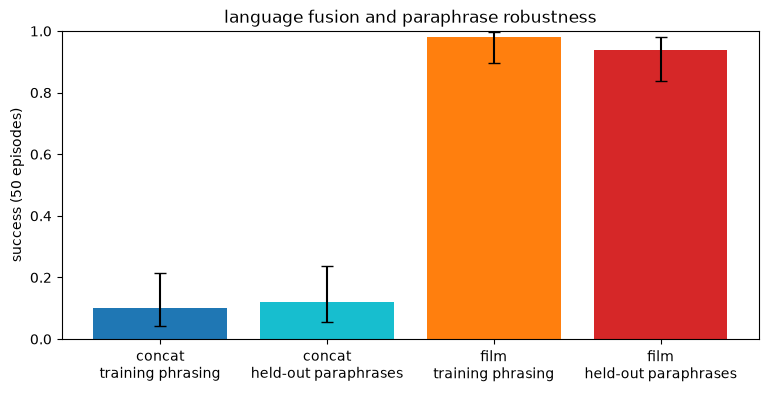

In [5]:
labels = [f"{f}\n{n}" for f, n in table]; s = np.array([r["success"] for r in table.values()])
ci = np.array([r["ci"] for r in table.values()])
plt.figure(figsize=(9, 4)); plt.bar(labels, s, yerr=[s - ci[:, 0], ci[:, 1] - s], capsize=4, color=["tab:blue", "tab:cyan", "tab:orange", "tab:red"])
plt.ylim(0, 1); plt.ylabel("success (50 episodes)"); plt.title("language fusion and paraphrase robustness"); plt.show()

### Watch it: late fusion vs FiLM on the same instruction
Same scene, same sentence. Concatenating the language vector at the end (left) vs letting it modulate the vision features (right).

In [6]:
from vlacourse import showcase as sc
a, b = ("film", "training phrasing"), ("concat", "training phrasing")
sc.compare(env, {"concat (late fusion)": LangChunkPolicy(nets["concat"], ds, env, emb, device=device, ensemble=True),
                  "FiLM (early fusion)": LangChunkPolicy(nets["film"], ds, env, emb, device=device, ensemble=True)},
           seed=sc.pick_seed(table[a], table[b], 60_000), title="90 concat vs FiLM")

90 concat vs FiLM: concat (late fusion): failed | FiLM (early fusion): success


[False, True]